# <font color=#023F7C> **Machine Learning and Deep Learning**

---



<font color=#023F7C>**Hi! PARIS DataBootcamp 2026 🚀**</font> <br>


<img src = https://www.hi-paris.fr/wp-content/uploads/2020/09/logo-hi-paris-retina.png width = "300" height = "200" >


**Name**: ...           <br>
**School**: ...         <br>
**Group number**: ...    <br>
**Track**: ...           <br>
**Teaching Assistants**: Thibault Porssut, Marguerite Leang, Aïssa Abdelaziz and Awais Sani, Machine Learning Research Engineer @ Hi! PARIS

# **1. Important guidelines**
As Generative AI tools like ChatGPT, Copilot, and Gemini become deeply embedded in academic life, understanding their true impact on students has never been more critical. This synthetic [Impact of AI on Students dataset](https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students/data) provides a rich, multi-dimensional snapshot of student interactions with AI—spanning academic outcomes, behavioral patterns, institutional context, and psychological well-being. It offers fertile ground for exploring the benefits and risks of AI adoption in higher education.
> **Our Objective:**
> We want to explore the impact of AI usage on student behavior and performance using the provided dataset (`ai_student_impact_dataset.csv`). Containing data across 50,000 students, this synthetic dataset captures how Generative AI tool usage shapes student performance, skill development, mental health, and burnout risk.
> *Note: The dataset has already been preprocessed and is free of missing values and outliers, allowing us to focus entirely on machine learning modeling.*

> **Core Variables of Focus:**
> We will examine the impact of our main independent variable, **`Weekly_GenAI_Hours`**, on two critical targets:
> 1. **`Burnout_Risk_Level`** (student mental health)
> 2. **`GPA_Change`** (calculated as **`Post_Semester_GPA` - `Pre_Semester_GPA`**)
>
>
<!-- > **Why Machine Learning?**
> Relying solely on simple bivariate correlations can often lead to misleading conclusions ([see spurious correlations](https://www.tylervigen.com/spurious-correlations)). Building a Machine Learning model allows us to analyze multi-variable, non-linear relationships much more robustly.<br> -->
> **Notebook Structure:**
> Because our target variables have different data types, we will treat this as two distinct machine learning problems:
> * **Part 1 (Classification):** Predicting **`Burnout_Risk_Level`** (a categorical variable with three levels: *Low*, *Medium*, or *High*).
> * **Part 2 (Regression):** Predicting **`GPA_Change`** (a continuous target value ranging between -3 and 3).
>
>


**<font size='5'><u>How to work on this notebook</u>**</font> <br>
The notebook is split in two parts: Machine Learning and Deep Learning.

- **Beginner track**: You only have to complete the Machine Learning (Explanability and Deep Learning section are optionnal.)
- **Intermediate track**: Please complete Machine Learning, Deep Learning and Explanability.

**<font size='5'><u>Bootcamp deliverables</u>**</font> <br>

Here are the two deadlines for the bootcamp deliverables:
- <u>**Friday 12:30 PM**</u>: <br> Send us the "`Machine Learning and Deep Learning`" notebooks (no need to send us data cleaning) <br>
    - **Each group should send its own notebooks**
    - Don't forget to complete the start of the notebook with your information (name, school, group number and track)
    
- <u>**Friday 2:30PM**</u>: <br>Send us the group slides <br>
    - You can send us a single powerpoint per group (no need to send us one per group member)
    - Don't forget to add your group number as well as who is in your group (name, school and track) to the slides

Send both the notebooks and the slides at `data-event@hi-paris.fr`

**<font size='5'><u>Need help ? 🙏</u>**</font> <br>

Later in the week, we will drop on the drive the Machine Learning course (Beginner track) and the `Machine_Learning_Beginner_DB2026.ipynb` notebook for those who need help with the Machine Learning part.

**Don't hesitate to ask questions to the bootcamp organizers/staff members if you need help.**


# **2. Machine Learning**

Let's start by importing the libraries needed for this notebook.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

Please download/copy the dataset on your cloud, or  drag/drop it on the left panel `files/`. <br>
Now import the raw dataset `ai_student_impact_dataset.csv` using pandas.

In [11]:
df= pd.read_csv("/content/ai_student_impact_dataset.csv")
df['GPA_Change'] = df['Post_Semester_GPA'] - df['Pre_Semester_GPA']
df.head()


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,GPA_Change
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High,-0.025
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low,-0.125
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium,0.101
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium,0.211
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium,0.163


### **2.1 Feature Engineering & Splits**

In [12]:
# Preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder,LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer


**<u>Question 2.1.1:</u>** **<br>Drop the dependent variables:**<br> `Post_Semester_GPA`, `Skill_Retention_Score`, `Traditional_Study_Hours`, and `Anxiety_Level_During_Exams`.<br> *(Note: We keep `Pre_Semester_GPA` to give the model a baseline).*

To build our predictive model, you can only use data available *before* the outcome happens (dependent variables). If you want to predict Burnout and GPA Change at the end of the semester, you must drop variables that are consequences of the semester (Outcomes).


In [13]:
df=df.drop(columns=["Student_ID", "Post_Semester_GPA", "Skill_Retention_Score", "Traditional_Study_Hours", "Anxiety_Level_During_Exams"])
df.head()

,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Perceived_AI_Dependency,Institutional_Policy,Burnout_Risk_Level,GPA_Change
0,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,5,Allowed_With_Citation,High,-0.025
1,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,3,Allowed_With_Citation,Low,-0.125
2,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,5,Strict_Ban,Medium,0.101
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,2,Allowed_With_Citation,Medium,0.211
4,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,4,Allowed_With_Citation,Medium,0.163


**<u>Question 2.1.2</u>**:<br> **Create $y_{class}, X_{class}$ and $y_{regress}, X_{regress}$ then [split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html#sklearn.model_selection.train_test_split) them into train and test sets.**


In [14]:
x_class=df.drop(columns=["Burnout_Risk_Level", "GPA_Change"])
x_regress=df.drop(columns=["Burnout_Risk_Level", "GPA_Change"])
y_class=df['Burnout_Risk_Level']
y_regress=df['GPA_Change']
x_class_train,x_class_test,y_class_train,y_class_test=train_test_split(x_class, y_class, stratify=y_class, test_size=0.2)
x_regress_train,x_regress_test,y_regress_train,y_regress_test=train_test_split(x_regress, y_regress, test_size=0.2)


**<u>Question 2.1.3:</u>** <br>**Encode the categorical variables with:**<br>
  * *[One-Hot Encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) :* `Major_Category`, `Primary_Use_Case`, `Institutional_Policy` (Nominal data)
  * *[Ordinal Encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html):* `Year_of_Study`, `Prompt_Engineering_Skill` (Ordered data)
  * *[Label Encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html):* `Burnout_Risk_Level` (The Target variable $y$)

> ***Note:*** <br>
**Encoding Features (Inputs):**
  *Ordinal vs. One-Hot* <br>
  Variables like `Year_of_Study` and `Prompt_Engineering_Skill` possess a natural hierarchy (e.g., "Beginner" < "Intermediate" < "Advanced"). For these, we use ***OrdinalEncoder()***, which assigns progressive integers to preserve this meaning, helping the model understand that "Advanced" is mathematically greater than "Beginner". By contrast, nominal variables (like `Major_Category`) have no intrinsic ranking. If we used ordinal encoding here, the model would falsely assume one major is "greater" than another. Instead, we use ***One-Hot Encoding***, which creates independent binary columns for each category, preventing artificial ordering.<br>
**Encoding the Target (Output):**
 *Label Encoding* <br>
 While Ordinal and One-Hot encoders are designed for our input features ($X$), ***LabelEncoder()*** is specifically built to encode our categorical target variable ($y$). It simply assigns an integer to each class (usually based on alphabetical order). Since the target acts merely as a "bucket" or "ID tag" for the model's final prediction, internal ranking does not distort the algorithm's mathematical calculations.


In [15]:
# Reset index so the pieces we build can be concatenated correctly later
x_class_train = x_class_train.reset_index(drop=True)
x_class_test = x_class_test.reset_index(drop=True)
x_regress_train = x_regress_train.reset_index(drop=True)
x_regress_test = x_regress_test.reset_index(drop=True)

onehot_cols = ["Major_Category", "Primary_Use_Case", "Institutional_Policy"]
ordinal_cols = ["Year_of_Study", "Prompt_Engineering_Skill"]
year_order = ["Freshman", "Sophomore", "Junior", "Senior", "Graduate"]
skill_order = ["Beginner", "Intermediate", "Advanced"]

##  ONE-HOT ENCODING (nominal columns)
# Classification split
onehot_encoder = OneHotEncoder(sparse_output=False)
x_class_train_cat = onehot_encoder.fit_transform(x_class_train[onehot_cols])
x_class_test_cat = onehot_encoder.transform(x_class_test[onehot_cols])

onehot_features = onehot_encoder.get_feature_names_out()
x_class_train_cat = pd.DataFrame(x_class_train_cat, columns=onehot_features)
x_class_test_cat = pd.DataFrame(x_class_test_cat, columns=onehot_features)

# Regression split (own fitted encoder, different rows)
onehot_encoder_regress = OneHotEncoder(sparse_output=False)
x_regress_train_cat = onehot_encoder_regress.fit_transform(x_regress_train[onehot_cols])
x_regress_test_cat = onehot_encoder_regress.transform(x_regress_test[onehot_cols])
x_regress_train_cat = pd.DataFrame(x_regress_train_cat, columns=onehot_features)
x_regress_test_cat = pd.DataFrame(x_regress_test_cat, columns=onehot_features)

##  ORDINAL ENCODING (ordered columns)
ordinal_encoder = OrdinalEncoder(categories=[year_order, skill_order])
x_class_train_ord = ordinal_encoder.fit_transform(x_class_train[ordinal_cols])
x_class_test_ord = ordinal_encoder.transform(x_class_test[ordinal_cols])
x_class_train_ord = pd.DataFrame(x_class_train_ord, columns=ordinal_cols)
x_class_test_ord = pd.DataFrame(x_class_test_ord, columns=ordinal_cols)

ordinal_encoder_regress = OrdinalEncoder(categories=[year_order, skill_order])
x_regress_train_ord = ordinal_encoder_regress.fit_transform(x_regress_train[ordinal_cols])
x_regress_test_ord = ordinal_encoder_regress.transform(x_regress_test[ordinal_cols])
x_regress_train_ord = pd.DataFrame(x_regress_train_ord, columns=ordinal_cols)
x_regress_test_ord = pd.DataFrame(x_regress_test_ord, columns=ordinal_cols)

##  LABEL ENCODING (target, classification only)
label_encoder = LabelEncoder()
y_class_train = label_encoder.fit_transform(y_class_train)
y_class_test = label_encoder.transform(y_class_test)

**<u>Question 2.1.3</u>**: <br>
**Scale the continuous variables using either `StandardScaler` (standardization) or `MinMaxScaler` (normalization).** Finalize by building your new dataframe.<br>





In [16]:
numeric_cols = ["Pre_Semester_GPA", "Weekly_GenAI_Hours", "Tool_Diversity", "Perceived_AI_Dependency"]

## STANDARD SCALER
std_scaler = StandardScaler()
x_class_train_cont = std_scaler.fit_transform(x_class_train[numeric_cols])
x_class_test_cont = std_scaler.transform(x_class_test[numeric_cols])
x_class_train_cont = pd.DataFrame(x_class_train_cont, columns=numeric_cols)
x_class_test_cont = pd.DataFrame(x_class_test_cont, columns=numeric_cols)

std_scaler_regress = StandardScaler()
x_regress_train_cont = std_scaler_regress.fit_transform(x_regress_train[numeric_cols])
x_regress_test_cont = std_scaler_regress.transform(x_regress_test[numeric_cols])
x_regress_train_cont = pd.DataFrame(x_regress_train_cont, columns=numeric_cols)
x_regress_test_cont = pd.DataFrame(x_regress_test_cont, columns=numeric_cols)

# Columns left untouched
remaining_cols = [c for c in x_class_train.columns if c not in onehot_cols + ordinal_cols + numeric_cols]

## MERGE CATEGORICAL, ORDINAL, CONTINUOUS AND REMAINING VARIABLES
x_class_train_scaled = pd.concat([x_class_train_cont, x_class_train_ord, x_class_train_cat, x_class_train[remaining_cols]], axis=1)
x_class_test_scaled = pd.concat([x_class_test_cont, x_class_test_ord, x_class_test_cat, x_class_test[remaining_cols]], axis=1)

x_regress_train_scaled = pd.concat([x_regress_train_cont, x_regress_train_ord, x_regress_train_cat, x_regress_train[remaining_cols]], axis=1)
x_regress_test_scaled = pd.concat([x_regress_test_cont, x_regress_test_ord, x_regress_test_cat, x_regress_test[remaining_cols]], axis=1)

### **2.2 Classification: Burnout Prediction**
Now that our dataset has been preprocessed selecting the relevant features, we can use it to train Machine Learning models.





In [17]:
# Metrics for evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix,
    classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score
)

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier,XGBRegressor



**Your Objective:**
Predict the burnout level of the students



<u>**Question 2.2.1**:</u> <br>  **Choose three classification models** seen during the cours and justify your choice.

We select **Logistic Regression**, **Random Forest**, and **XGBoost (Boosting)** — , covering increasing levels of complexity.

1. **Logistic Regression**
   - Complexity: **Low**, with a single hyperparameter (C: regularization strength) —
     makes it a fast, interpretable baseline to compare more complex models against.
   - Well suited as a first model since our features are already structured/tabular
     (numbers, encoded categories) rather than unstructured data.

2. **Random Forest**
   - The course highlights that Random Forest **prevents overfitting**: individual
     trees can make mistakes, but the forest averages out these errors — valuable
     here given the noisy, human-behavior nature of our target (burnout risk).
   - Complexity: **High**, with hyperparameters like `n_estimators` and `max_features`,
     letting us tune capacity if the simpler Logistic Regression underfits.

3. **XGBoost (Extreme Gradient Boosting)**
   - trees are trained **sequentially**, each new tree focusing on correcting the errors  of the previous ones, giving higher weight to hard/misclassified
     cases at every iteration.
   - Described as converting "weak to strong" learners into a single highly accurate
     predictor — typically the strongest performer among the models covered.
   - Complexity: **High**, with the richest hyperparameter set (`n_estimators`,
     `learning_rate`, `subsample`), allowing fine control.

<u>**Question 2.2.2**:</u> <br> **Train one model** among the three selected model using .fit(X_train_scaled, y_train).

In [18]:
rf_model = RandomForestClassifier()
rf_model.fit(x_class_train_scaled, y_class_train)

RandomForestClassifier()

<u>**Question 2.2.3**:</u> <br> **FIRST model: predict on TRAIN/TEST, then print Test Accuracy, Test Recall, Test F1.**

> ***Help:***<br>
The `.predict()` function should be used on the feature of the test set (X_test)*. [page](https://scikit-learn.org/stable/getting_started.html)<br>
*`accuracy_score()`, `recall_score()`, `f1_score()`
find all metrics here: [page](https://scikit-learn.org/stable/api/sklearn.metrics.html)*<br>
*Since all the features selected in the dataset are equally important, make sure to specify the averaging method when computing metrics. For `recall_score` and `f1_score`, use `average="macro"` so that both classes are weighted equally.*





In [19]:
# Predict on both train and test sets
y_train_pred = rf_model.predict(x_class_train_scaled)
y_test_pred = rf_model.predict(x_class_test_scaled)

# Compute test metrics
test_accuracy = accuracy_score(y_class_test, y_test_pred)
test_recall = recall_score(y_class_test, y_test_pred, average="macro")
test_f1 = f1_score(y_class_test, y_test_pred, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Recall:   {test_recall:.4f}")
print(f"Test F1:       {test_f1:.4f}")

Test Accuracy: 0.5027
Test Recall:   0.4967
Test F1:       0.5058


<u>**Question 2.2.4**:</u> <br> **Train and evaluate the two other models**, but this time use `classification_report` to display all metrics per class.

In [20]:
#  Model 2: Logistic Regression
log_reg_model = LogisticRegression(max_iter=1000)
log_reg_model.fit(x_class_train_scaled, y_class_train)

y_test_pred_lr = log_reg_model.predict(x_class_test_scaled)

print("Logistic Regression - Classification Report")
print(classification_report(y_class_test, y_test_pred_lr))

#  Model 3: XGBoost Classifier
xgb_model = XGBClassifier(eval_metric="mlogloss")
xgb_model.fit(x_class_train_scaled, y_class_train)

y_test_pred_xgb = xgb_model.predict(x_class_test_scaled)

print("XGBoost - Classification Report")
print(classification_report(y_class_test, y_test_pred_xgb))

Logistic Regression - Classification Report
              precision    recall  f1-score   support

           0       0.68      0.46      0.55      2497
           1       0.55      0.48      0.51      3274
           2       0.49      0.62      0.54      4229

    accuracy                           0.54     10000
   macro avg       0.57      0.52      0.54     10000
weighted avg       0.55      0.54      0.54     10000

XGBoost - Classification Report
              precision    recall  f1-score   support

           0       0.63      0.46      0.53      2497
           1       0.51      0.47      0.49      3274
           2       0.47      0.57      0.52      4229

    accuracy                           0.51     10000
   macro avg       0.54      0.50      0.51     10000
weighted avg       0.52      0.51      0.51     10000



**Why is Recall the most important metric for the "High" Burnout class?**

* When evaluating a model, **Accuracy** can be highly misleading. A model could achieve high accuracy simply by predicting the majority class (e.g., "Medium" burnout) every time, while completely ignoring the worst-case scenarios.

* For our specific use case, we are trying to detect students at high risk. Therefore, we must focus on **Recall** (Sensitivity).

* Recall answers a vital question: "Out of all the students who were **ACTUALLY** in high burnout, how many did our model successfully catch?"

* **High Accuracy but Low Recall:** The model looks good on paper, but we are missing many students in severe distress (**False Negatives**).

*  **High Recall but Lower Precision:** The model successfully catches almost all students in distress, even if it occasionally raises a false alarm for a healthy student (**False Positives**).

* Because the cost of missing a student in high burnout is far more dangerous than checking in on a healthy student, we must prioritize hyperparameters that maximize **Recall** for the "High" class, accepting a slight drop in **Precision** as a necessary trade-off.

<u>**Question 2.2.5**:</u> <br>**Find the best model** by TEST Recall for the High burnout class among the three model selected and show its TEST confusion matrix.

> *Help: Look at [recall_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html) , [confusion_matrix()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)* and [ConfusionMatrixDisplay()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay) of your best model.

Random Forest       - Recall (High): 0.4802
Logistic Regression - Recall (High): 0.4630
XGBoost              - Recall (High): 0.4614


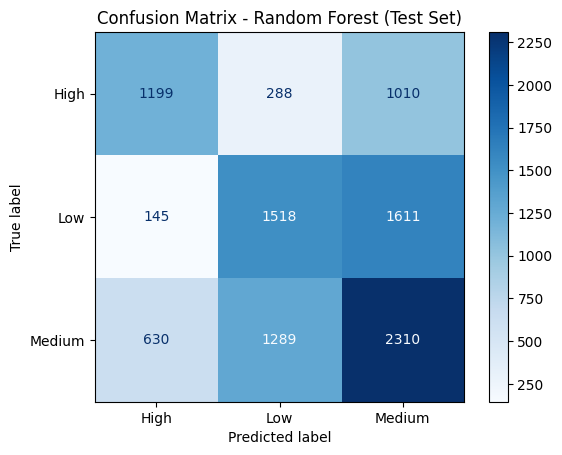

In [21]:
# Get the index corresponding to the "High" class from the LabelEncoder
high_idx = list(label_encoder.classes_).index("High")

# Recall for the "High" class only, for each model
recall_rf  = recall_score(y_class_test, y_test_pred,     labels=[high_idx], average=None)[0]
recall_lr  = recall_score(y_class_test, y_test_pred_lr,  labels=[high_idx], average=None)[0]
recall_xgb = recall_score(y_class_test, y_test_pred_xgb, labels=[high_idx], average=None)[0]

print(f"Random Forest       - Recall (High): {recall_rf:.4f}")
print(f"Logistic Regression - Recall (High): {recall_lr:.4f}")
print(f"XGBoost              - Recall (High): {recall_xgb:.4f}")
# Best model = Random Forest (highest Test Recall for "High" burnout)
best_model_name = "Random Forest"
best_pred = y_test_pred

# Confusion matrix of the best model
cm = confusion_matrix(y_class_test, best_pred, labels=label_encoder.transform(label_encoder.classes_))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name} (Test Set)")
plt.show()


### **2.3 Regression: GPA Change**

**Now your Objective is:**
Predict the GPA change of the students

In [22]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# hyperparameter tuning
from sklearn.model_selection import GridSearchCV

<u>**Question 2.3.1**:</u> <br>
**Train one regression model** (e.g., XGBRegressor). Evaluate it using NRMSE, $R^2$, and **MAE (Mean Absolute Error)**.<b>

> *Notice: Why MAE? Because it keeps the exact same unit as your target. If MAE = 0.15, it means "On average, the model's prediction is wrong by 0.15 GPA points."*

In [23]:
regressor=XGBRegressor()
regressor.fit(x_regress_train_scaled, y_regress_train)
regress_pred=regressor.predict(x_regress_test_scaled)
regress_RMSE=mean_squared_error(y_pred=regress_pred, y_true=y_regress_test)**0.5
regress_NRMSE=regress_RMSE/(y_regress_test.max()-y_regress_test.min())
regress_MAE=mean_absolute_error(y_pred=regress_pred, y_true=y_regress_test)
regress_r2=r2_score(y_pred=regress_pred, y_true=y_regress_test)
print(f"normalized root mean squared error:{regress_NRMSE}")
print(f"mean absolute error:{regress_MAE}")
print(f"r2 score:{regress_r2}")

normalized root mean squared error:0.08787280533761004
mean absolute error:0.1282308218600312
r2 score:0.2310929641263999


<u>**Question 2.3.2**:</u> <br> **Tiny GridSearch to improve MAE.**

> ***Help:** Try `GridSearchCV` [page](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) on the previous model to find hyperparameters that lower the MAE.<br>
Report the best hyperparameters (`.best_params_`) and the best cross-validated MAE (`.best_score_`). Then re-fit the tuned model and print the Test MAE.*

> **Notes (keep it simple):**<br>
Keep the grid tiny (2–3 values per parameter) to avoid long runs; set `cv=3`.
Compare against your baseline Test Recall (before tuning). One line is enough.


In [24]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.05, 0.1, 0.2],
}

grid_search = GridSearchCV(
    estimator=XGBRegressor(),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=3,
)
grid_search.fit(x_regress_train_scaled, y_regress_train)

print("Best hyperparameters:", grid_search.best_params_)
print(f"Best cross-validated MAE: {-grid_search.best_score_:.4f}")

best_regressor = grid_search.best_estimator_
tuned_pred = best_regressor.predict(x_regress_test_scaled)
tuned_MAE = mean_absolute_error(y_pred=tuned_pred, y_true=y_regress_test)
print(f"Test MAE (tuned): {tuned_MAE:.4f}")

print(f"Baseline Test MAE was 0.1281 vs tuned Test MAE {tuned_MAE:.4f} "
      f"({'improved' if tuned_MAE < 0.1281 else 'did not improve'}).")

Best hyperparameters: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200}
Best cross-validated MAE: 0.1263
Test MAE (tuned): 0.1254
Baseline Test MAE was 0.1281 vs tuned Test MAE 0.1254 (improved).


The GridSearch tuning slightly improved the model, reducing the Test MAE by about
0.0023 GPA points (~1.8% relative improvement). This is a modest but real gain —
the default XGBoost hyperparameters were already reasonably close to optimal for
this tiny grid, so further improvement would likely require a wider search space,
more features.

# **3. Explainability with shap**

The `shap` library (SHapley Additive exPlanations) is a Python library used for explaining the output of machine learning models. <br> It provides a unified framework for interpreting complex models and understanding the contributions of individual features to model predictions. <br>

Shap is particularly useful for understanding black-box models like boosting, random forests, and deep neural networks, among others. <br>
It can also be used with any classification model.

**Let's install and import the shap library.**

In [25]:
!pip install shap

In [26]:
import shap
shap.initjs()

Shap is very heavy and takes a long time to compute. <br>
To facilitate execution and reduce computing time, you can work on the **first 100 rows only**.

> ***Note:** You can use either the train features (`X_train`) or the test features (`X_test`) to compute shap values*

In [36]:
df_shap =x_class_train_scaled[:100]

<u>**Question 3.1**:</u> <br>
**Create an object `explainer` that can compute shap values.** <br>

*<u>Help</u>: You can use `shap.Explainer` for any trained classification model as input.* <br>
*For tree based models, you can use `shap.TreeExplainer`*.


In [39]:
explainer=shap.TreeExplainer(rf_model)

**Now, compute the shap values of a model with `explainer.shap_values`.** <br>
If it takes too much time, you can reduce to 100-500 values.

In [41]:
shap_values=explainer.shap_values(df_shap)

<u>**Question 3.2**:</u> <br>
**Display the summary plot of shap values with `shap.summary_plot(...., plot_type=bar)`.**

*Make sure you use `shap_values[:, :, 2]` in your plot and not every shap value computed but specifically for High Burnout class *

/tmp/ipykernel_737/2279198146.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:, :, 2], df_shap, plot_type="bar")


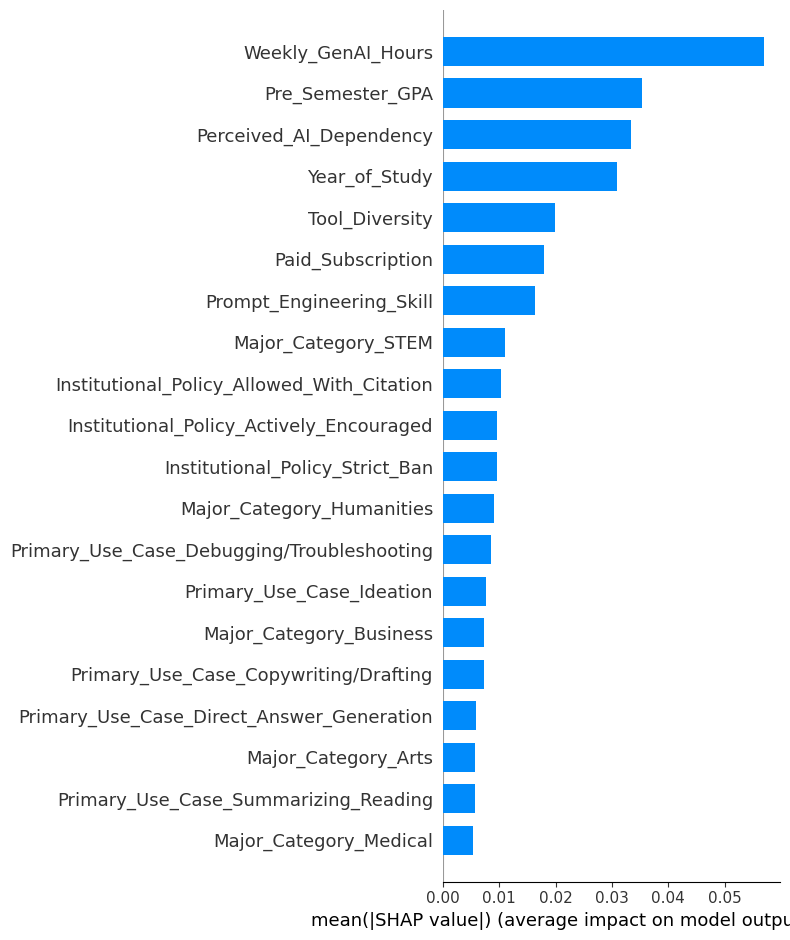

In [42]:
shap.summary_plot(shap_values[:, :, 2], df_shap, plot_type="bar")

<u>**Question 3.4**:</u> <br>
**Use the same shap plot as previously but replace `plot_type="bar"` with `plot_type="dot"`.** <br>
**And add the data you used to compute shap_values in `features=...`.**

**Explain what you have understood about this plot**:
- **Which variables are important in terms of explainability ?**
- **How does the values of the important variables affect predictions ?**

/tmp/ipykernel_737/3038468145.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:, :, 2], plot_type="dot", features=df_shap)


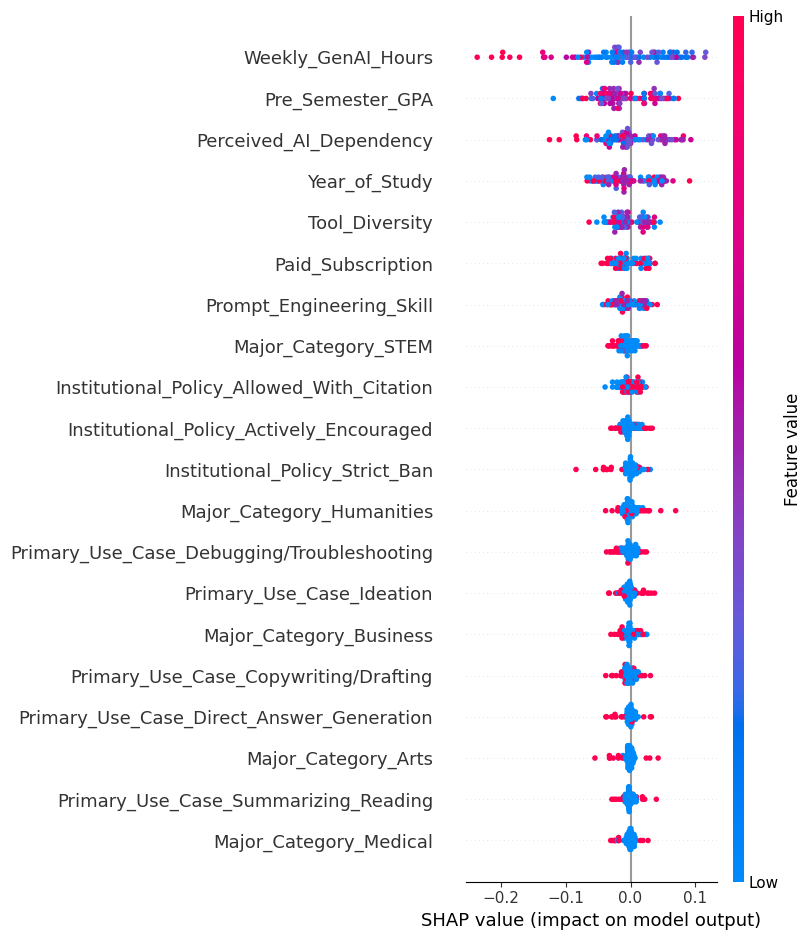

In [44]:
shap.summary_plot(shap_values[:, :, 2], plot_type="dot", features=df_shap)

**Weekly_GenAI_Hours** is by far the most important feature. High values (pink/red) push predictions down (toward "not High" burnout), while low values pull predictions up — so students who use GenAI tools more are actually less likely to be flagged as High burnout risk.
**Pre_Semester_GPA** is the 2nd most important feature, but the effect is smaller and more mixed — no clean color separation, so its influence on High burnout is present but less clear-cut than GenAI hours.
**Perceived_AI_Dependency** is 3rd: colors are mixed on both sides, meaning it matters but doesn't cleanly push predictions one direction — likely interacts with other features.


Everything below (Year_of_Study, Tool_Diversity, Paid_Subscription, all the one-hot Major/Use-Case/Policy columns) has SHAP values clustered tightly near 0 , these features barely move the model's prediction; they add little explanatory power individually.

1. Features at the top of the Y-axis are the most important predictors for High Burnout.
2. Look at the color (Feature Value) and the X-axis (SHAP Value / Impact on output).
   - If red dots are piled up on the right side of the vertical line (SHAP > 0), it means
     that a HIGH value of that feature INCREASES the risk of High Burnout.
   - If blue dots are on the right, it means a LOW value of that feature increases the risk.

=> high weekly GenAI hours and high baseline GPAs seem to push away form the high burnout

# **4. Deep Learning**

We will start by importing one of Python's Deep Learning libraries `tensorflow`/`keras`.

In [46]:
from keras.models import Sequential
from keras.layers import Dense, Dropout

In the following cells, `dataset` should be the dataset you transformed with data pre-processing (Onehotencoded, LabelEncoder,...). <br>
You should run the following cells to prepare the data to train a Deep Learning model.

<u>**Question 4.1**:</u> <br>
**Make a small neural network model using `tensorflow`/`keras`, and print the accuracy**

*Note: You can use the following elements to train the neural network* <br>
- *`tf.keras.Sequential`*
- *`layers.Dense(INTEGER, activation='relu')`*,
- *`tf.keras.losses.BinaryCrossentropy`*
- *`model.compile(optimizer='adam', ...)`*
- *`model.fit`*
- *`model.evaluate`* with epoch ~= 10

In [48]:
import tensorflow as tf
# One-hot encode the target for a multi-output binary-crossentropy setup
y_ohe = OneHotEncoder(sparse_output=False)
y_class_train_ohe = y_ohe.fit_transform(y_class_train.reshape(-1, 1))
y_class_test_ohe = y_ohe.transform(y_class_test.reshape(-1, 1))

model = tf.keras.Sequential([
    Dense(32, activation='relu', input_shape=(x_class_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(y_class_train_ohe.shape[1], activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

model.fit(x_class_train_scaled, y_class_train_ohe, epochs=10)

test_loss, test_accuracy = model.evaluate(x_class_test_scaled, y_class_test_ohe)
print(f"Test Accuracy: {test_accuracy:.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5141 - loss: 0.5662
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5318 - loss: 0.5490
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5327 - loss: 0.5480
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5343 - loss: 0.5473
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5355 - loss: 0.5468
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5364 - loss: 0.5465
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5357 - loss: 0.5462
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5371 - loss: 0.5458
Epoch 9/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5374 - loss: 0.5457
Epoch 10/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5387 - loss: 0.5455
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5337 - loss: 0.5465
Test Accuracy: 0.5337
